# ICE Task: CNN that Recognises Nicolas Cage

**Student:** Khodani Mbovane (ST10524773)
**Institution:** The Independent Institute of Education | Emeris
**Task:** Classify an image as "Nicolas Cage" or "Not Nicolas Cage"

### How to run (plug and play)
1. Open in Google Colab or Jupyter.
2. Optional: paste a SerpAPI key in Step 1 to use Google Images. Leave blank to use DuckDuckGo (no key). Downloads are capped at 500 images.
3. Click **Run all**. Images are collected automatically, the model trains, and all submission screenshots are saved to `screenshots/`.

### Approach
| Step | What I do |
|---|---|
| 1 | Set up packages and settings |
| 2 | Collect images automatically through an image search API |
| 3 | Load, split and inspect the data (Screenshot 1) |
| 4 | Build a CNN using MobileNetV2 transfer learning |
| 5 | Train and plot the training history (Screenshot 2) |
| 6 | Evaluate on a held-out validation set |
| 7 | Show correct predictions (Screenshots 3 and 4) |
| 8 | Bonus: test on unseen web images |

## Step 1: Setup and settings
This is the only cell that needs editing, and editing it is optional.

In [1]:
# ===================== SETTINGS (optional to change) =====================
SERPAPI_KEY      = ""        # paste a free key from serpapi.com for Google Images, or leave blank
IMAGE_SOURCE     = "auto"    # "auto" = Google if key above, else DuckDuckGo
MAX_IMAGES       = 500       # hard cap on total images downloaded (training + bonus test)
QUICK_MODE       = True      # True = fewer training epochs, False = longer training
REDOWNLOAD       = False     # True = ignore cached images and search again
# =========================================================================

import subprocess, sys, importlib
for pkg, mod in [("ddgs", "ddgs"), ("requests", "requests"), ("pillow", "PIL"),
                 ("scikit-learn", "sklearn"), ("matplotlib", "matplotlib"), ("tensorflow", "tensorflow")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        print(f"Installing {pkg}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, glob, time, hashlib, io, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, requests, matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

SERPAPI_KEY      = SERPAPI_KEY or os.environ.get("SERPAPI_KEY", "")
BONUS_IMAGES     = 18                                   # reserved for the Step 8 bonus test
TRAIN_IMAGES     = MAX_IMAGES - BONUS_IMAGES             # 482 when MAX_IMAGES = 500
CAGE_BUDGET      = int(TRAIN_IMAGES * 0.4)               # 192 Cage images
NOT_BUDGET       = TRAIN_IMAGES - CAGE_BUDGET            # 290 non-Cage images
EPOCHS           = 10 if QUICK_MODE else 20
FINE_TUNE_EPOCHS = 4 if QUICK_MODE else 8
IMG_SIZE, BATCH_SIZE = 160, 32
CLASS_NAMES = ["Not Nicolas Cage", "Nicolas Cage"]       # label 0, label 1
CAGE_DIR, NOT_DIR = "data/nicolas_cage", "data/not_nicolas_cage"
os.makedirs("screenshots", exist_ok=True)
plt.rcParams.update({"figure.facecolor": "white", "axes.edgecolor": "black", "font.size": 10})

SOURCE = ("google" if SERPAPI_KEY else "duckduckgo") if IMAGE_SOURCE == "auto" else IMAGE_SOURCE
print(f"TensorFlow {tf.__version__} | GPU: {bool(tf.config.list_physical_devices('GPU'))} | Image source: {SOURCE}")

Installing ddgs...
TensorFlow 2.21.0 | GPU: True | Image source: duckduckgo


## Step 2: Collect images through an image search API
I use several search queries per class. The "Not Nicolas Cage" class deliberately includes similar-looking actors (hard negatives), ordinary people, animals and objects, so the model learns what Cage is *not*. Google's own Custom Search JSON API is closed to new customers, so Google Images results are accessed through SerpAPI, with DuckDuckGo as a free fallback. Downloads are capped at `MAX_IMAGES` (500): 192 Cage and 290 non-Cage images for training, plus 18 for the bonus test. Images are cached in `data/` so re-runs do not search again.

In [2]:
CAGE_QUERIES = ["Nicolas Cage", "Nicolas Cage face close up", "Nicolas Cage portrait",
                "Nicolas Cage red carpet", "Nicolas Cage smiling", "Nicolas Cage young",
                "Nicolas Cage interview", "Nicolas Cage headshot"]
NOT_CAGE_QUERIES = ["John Travolta face", "Johnny Depp face", "Keanu Reeves face", "Pedro Pascal face",
                    "Dwayne Johnson face", "Beyonce face", "Leonardo DiCaprio face", "Meryl Streep face",
                    "man portrait photo", "woman portrait photo", "elderly man portrait", "African man portrait",
                    "cat photo", "dog photo", "bird photo", "car photo", "landscape photo", "food photo"]

HEADERS = {"User-Agent": "Mozilla/5.0 (educational ICE task)"}

def search_google(query, n):
    urls, page = [], 0
    while len(urls) < n and page < 3:
        r = requests.get("https://serpapi.com/search.json", timeout=30, params={
            "engine": "google_images", "q": query, "ijn": page, "api_key": SERPAPI_KEY})
        r.raise_for_status()
        res = r.json().get("images_results", [])
        if not res:
            break
        urls += [x.get("original") or x.get("thumbnail") for x in res]
        page += 1
    return [u for u in urls if u][:n]

def search_duckduckgo(query, n):
    from ddgs import DDGS
    for attempt in range(3):
        try:
            return [x["image"] for x in DDGS().images(query, max_results=n) if x.get("image")]
        except Exception as e:
            print(f"   retry {attempt + 1} for '{query}' ({type(e).__name__})")
            time.sleep(5 * (attempt + 1))
    return []

def image_search(query, n):
    return search_google(query, n) if SOURCE == "google" else search_duckduckgo(query, n)

def fetch_image(url):
    """Download one image; return (md5 hash, PIL image) or None if unusable."""
    try:
        r = requests.get(url, headers=HEADERS, timeout=10); r.raise_for_status()
        img = Image.open(io.BytesIO(r.content)).convert("RGB")
        return (hashlib.md5(r.content).hexdigest(), img) if min(img.size) >= 80 else None
    except Exception:
        return None

def download(queries, out_dir, budget):
    """Download an even share per query, stopping once the class budget is reached."""
    os.makedirs(out_dir, exist_ok=True)
    per_query = -(-budget // len(queries))                  # ceiling division
    total = 0
    for q in queries:
        if total >= budget:
            break
        target = min(per_query, budget - total)
        ok = 0
        for url in image_search(q, target + 10):            # a few spare URLs for broken links
            if ok >= target:
                break
            got = fetch_image(url)
            if got and not os.path.exists(f"{out_dir}/{got[0]}.jpg"):
                got[1].save(f"{out_dir}/{got[0]}.jpg", quality=92); ok += 1
        print(f"  {q:<30} {ok:>3} saved"); total += ok
        time.sleep(1)
    return total

if REDOWNLOAD or len(glob.glob(f"{CAGE_DIR}/*.jpg")) < 20:
    print(f"Collecting up to {CAGE_BUDGET} Nicolas Cage images:");    download(CAGE_QUERIES, CAGE_DIR, CAGE_BUDGET)
    print(f"Collecting up to {NOT_BUDGET} Not Nicolas Cage images:"); download(NOT_CAGE_QUERIES, NOT_DIR, NOT_BUDGET)
else:
    print("Using cached images in data/ (set REDOWNLOAD = True to search again).")

n_cage, n_not = len(glob.glob(f"{CAGE_DIR}/*.jpg")), len(glob.glob(f"{NOT_DIR}/*.jpg"))
print(f"\nNicolas Cage: {n_cage} | Not Nicolas Cage: {n_not} | Total: {n_cage + n_not} (cap {TRAIN_IMAGES} + {BONUS_IMAGES} bonus = {MAX_IMAGES})")
assert n_cage >= 20 and n_not >= 20, "Too few images downloaded. Check the internet connection, or add a SerpAPI key in Step 1."

  Nicolas Cage                    24 saved
  Nicolas Cage face close up      24 saved
  Nicolas Cage portrait           24 saved
  Nicolas Cage red carpet         24 saved
  Nicolas Cage smiling            24 saved
  Nicolas Cage young              24 saved
  Nicolas Cage interview          24 saved
  Nicolas Cage headshot           24 saved
  John Travolta face              17 saved
  Johnny Depp face                17 saved
  Keanu Reeves face               17 saved
  Pedro Pascal face               17 saved
  Dwayne Johnson face             17 saved
  Beyonce face                    17 saved
  Leonardo DiCaprio face          17 saved
  Meryl Streep face               17 saved
  man portrait photo              17 saved
  woman portrait photo            17 saved
  elderly man portrait            17 saved
  African man portrait            17 saved
  cat photo                       17 saved
  dog photo                       17 saved
  bird photo                      17 saved
  car photo

**Data quality check.** Web results are noisy (posters, group photos, memes). I review the Cage images and list any wrong ones in `REMOVE` (first 8 characters of the title), then re-run this cell. Training still works if I skip this.

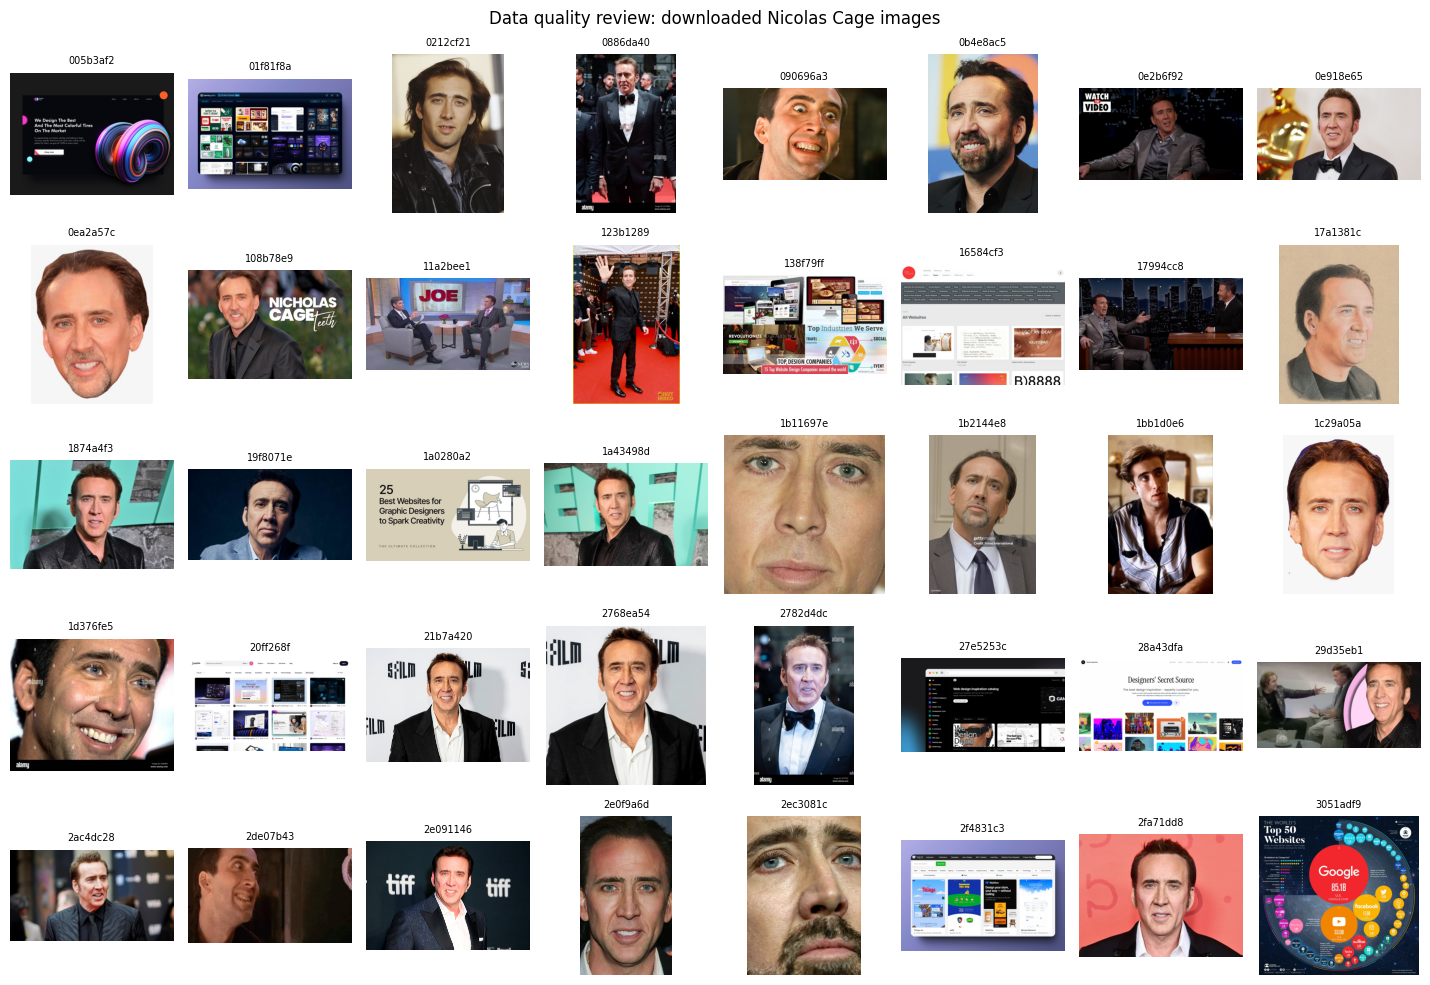

In [3]:
REMOVE = []      # e.g. ["3fa9c1d2", "b77e0a14"]
for prefix in REMOVE:
    for f in glob.glob(f"data/*/{prefix}*.jpg"):
        os.remove(f); print("Removed", f)

files = sorted(glob.glob(f"{CAGE_DIR}/*.jpg"))[:40]
cols = 8; rows = (len(files) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.8, rows * 2.0), squeeze=False)
for ax in axes.ravel(): ax.axis("off")
for ax, f in zip(axes.ravel(), files):
    ax.imshow(Image.open(f).convert("RGB")); ax.set_title(os.path.basename(f)[:8], fontsize=7)
plt.suptitle("Data quality review: downloaded Nicolas Cage images"); plt.tight_layout(); plt.show()

## Step 3: Load, split and inspect the data (Screenshot 1)

Training: 385 | Validation: 97 | Class weights: [0.83 1.26]


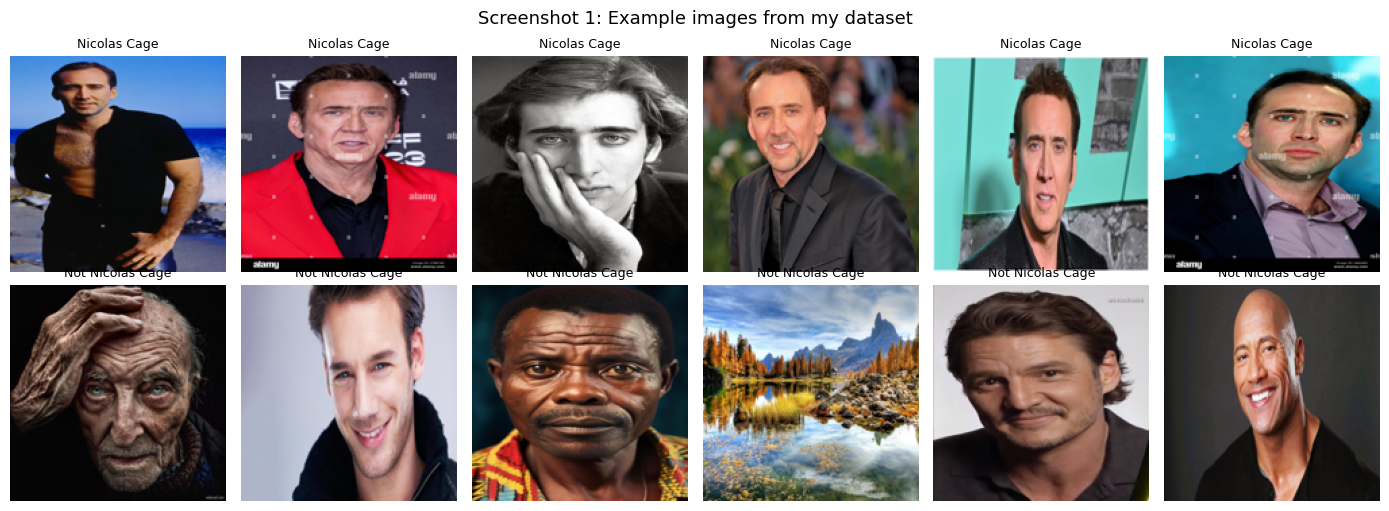

In [4]:
def load_image(path_or_img):
    img = Image.open(path_or_img) if isinstance(path_or_img, str) else path_or_img
    return np.asarray(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.uint8)

X, y, paths = [], [], []
for label, folder in [(1, CAGE_DIR), (0, NOT_DIR)]:
    for p in sorted(glob.glob(f"{folder}/*.jpg")):
        try:
            X.append(load_image(p)); y.append(label); paths.append(p)
        except Exception:
            pass
X, y, paths = np.stack(X), np.array(y), np.array(paths)
train_hashes = {os.path.basename(p)[:-4] for p in paths}

# Stratified 80/20 split keeps the class ratio the same in training and validation
X_train, X_val, y_train, y_val, p_train, p_val = train_test_split(
    X, y, paths, test_size=0.2, stratify=y, random_state=SEED)
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}      # balances the loss because non-Cage images outnumber Cage images

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(len(y_train), seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
print(f"Training: {len(y_train)} | Validation: {len(y_val)} | Class weights: {cw.round(2)}")

# Screenshot 1: example images from each class
fig, axes = plt.subplots(2, 6, figsize=(14, 5.2))
for row, label in enumerate([1, 0]):
    for ax, i in zip(axes[row], np.random.choice(np.where(y == label)[0], 6, replace=False)):
        ax.imshow(X[i]); ax.set_title(CLASS_NAMES[label], fontsize=9); ax.axis("off")
plt.suptitle("Screenshot 1: Example images from my dataset", fontsize=13); plt.tight_layout()
plt.savefig("screenshots/screenshot_1_dataset_examples.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 4: Build the CNN
- **Data augmentation** (flip, rotation, zoom, contrast) creates varied training images, which reduces overfitting on a small dataset.
- **Transfer learning:** MobileNetV2 (Sandler et al., 2018), pre-trained on ImageNet, provides the convolutional layers that already detect edges, textures and facial structure. I freeze them and train my own classification head (Chollet, 2021).
- **Output:** one sigmoid neuron giving P(Nicolas Cage); 0.5 is the decision threshold.

In [5]:
augment = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08),
                            layers.RandomZoom(0.15), layers.RandomContrast(0.15)], name="augmentation")
try:
    base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False
    PRETRAINED = True
except Exception as e:
    print("ImageNet weights unavailable, so a smaller CNN is trained from scratch instead:", type(e).__name__)
    PRETRAINED = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)
if PRETRAINED:
    x = keras.applications.mobilenet_v2.preprocess_input(x)   # scale pixels to [-1, 1]
    x = base(x, training=False)
else:                                                          # fallback: 4 conv blocks
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs, name="cage_detector")
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
print(f"Total parameters: {model.count_params():,} | Trainable: {sum(np.prod(w.shape) for w in model.trainable_weights):,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total parameters: 2,422,081 | Trainable: 164,097


## Step 5: Train and plot the training history (Screenshot 2)
Training runs in two phases: (1) train the new head with the base frozen, then (2) fine-tune the top 30 MobileNetV2 layers at a 100x smaller learning rate so the pre-trained features adapt to faces without being destroyed. Early stopping restores the best weights.

Epoch 1/10
13/13 - 12s - 941ms/step - accuracy: 0.6260 - loss: 0.7039 - val_accuracy: 0.8454 - val_loss: 0.3894
Epoch 2/10
13/13 - 1s - 49ms/step - accuracy: 0.7688 - loss: 0.4880 - val_accuracy: 0.8660 - val_loss: 0.3846
Epoch 3/10
13/13 - 0s - 36ms/step - accuracy: 0.8000 - loss: 0.4492 - val_accuracy: 0.8454 - val_loss: 0.3911
Epoch 4/10
13/13 - 1s - 43ms/step - accuracy: 0.8234 - loss: 0.3730 - val_accuracy: 0.8763 - val_loss: 0.3452
Epoch 5/10
13/13 - 0s - 36ms/step - accuracy: 0.8026 - loss: 0.3508 - val_accuracy: 0.8247 - val_loss: 0.3535
Epoch 6/10
13/13 - 0s - 35ms/step - accuracy: 0.8026 - loss: 0.4188 - val_accuracy: 0.7835 - val_loss: 0.4129
Epoch 7/10
13/13 - 0s - 35ms/step - accuracy: 0.8909 - loss: 0.3285 - val_accuracy: 0.8763 - val_loss: 0.3535
Epoch 8/10
13/13 - 1s - 43ms/step - accuracy: 0.8571 - loss: 0.3141 - val_accuracy: 0.8660 - val_loss: 0.3149
Epoch 9/10
13/13 - 1s - 43ms/step - accuracy: 0.8779 - loss: 0.2802 - val_accuracy: 0.8866 - val_loss: 0.3108
Epoch 10

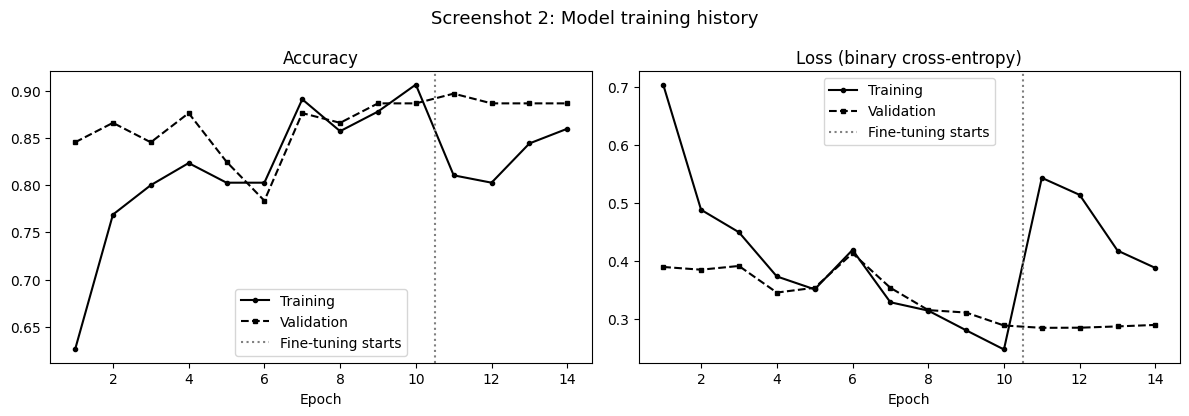

In [6]:
stop = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)]
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weight, callbacks=stop, verbose=2)
hist = {k: list(v) for k, v in h1.history.items()}
phase1_end = len(hist["loss"])

if PRETRAINED:                                   # phase 2: fine-tune top 30 layers
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy", metrics=["accuracy"])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS, class_weight=class_weight, callbacks=stop, verbose=2)
    for k, v in h2.history.items():
        hist[k] += v

# Screenshot 2: training history
ep = range(1, len(hist["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, m, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss (binary cross-entropy)")]:
    ax.plot(ep, hist[m], "k-o", ms=3, label="Training")
    ax.plot(ep, hist["val_" + m], "k--s", ms=3, label="Validation")
    if PRETRAINED: ax.axvline(phase1_end + 0.5, color="grey", ls=":", label="Fine-tuning starts")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.suptitle("Screenshot 2: Model training history", fontsize=13); plt.tight_layout()
plt.savefig("screenshots/screenshot_2_training_history.png", dpi=150, bbox_inches="tight"); plt.show()

## Step 6: Evaluate on the validation set

Validation accuracy: 89.69%

                  precision    recall  f1-score   support

Not Nicolas Cage      0.929     0.897     0.912        58
    Nicolas Cage      0.854     0.897     0.875        39

        accuracy                          0.897        97
       macro avg      0.891     0.897     0.894        97
    weighted avg      0.898     0.897     0.897        97



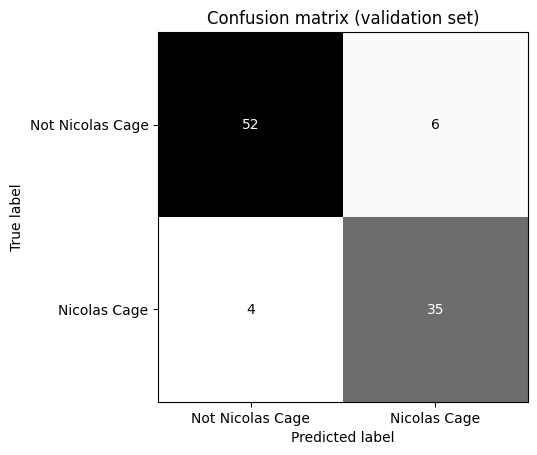

In [7]:
val_prob = model.predict(X_val, verbose=0).ravel()
val_pred = (val_prob >= 0.5).astype(int)
print(f"Validation accuracy: {(val_pred == y_val).mean():.2%}\n")
print(classification_report(y_val, val_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_val, val_pred, labels=[0, 1]),
                       display_labels=CLASS_NAMES).plot(cmap="Greys", colorbar=False)
plt.title("Confusion matrix (validation set)"); plt.show()

## Step 7: Correct predictions (Screenshots 3 and 4)

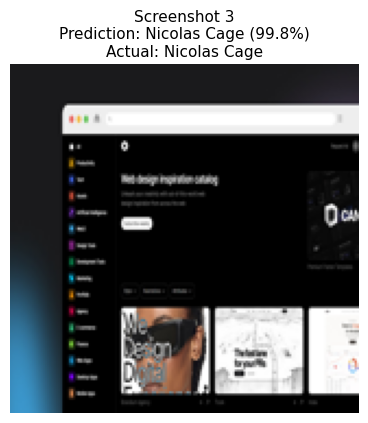

Model output -> Nicolas Cage with 99.8% confidence


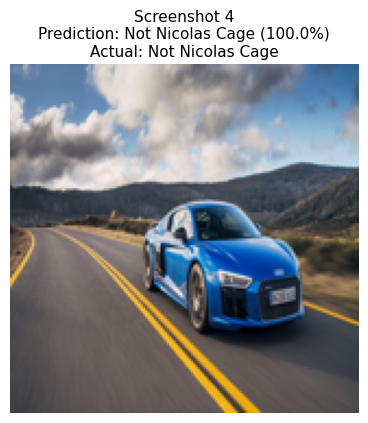

Model output -> Not Nicolas Cage with 100.0% confidence


In [8]:
def predict(img_array):
    p = float(model.predict(img_array[np.newaxis].astype("float32"), verbose=0)[0, 0])
    return ("Nicolas Cage", p) if p >= 0.5 else ("Not Nicolas Cage", 1 - p)

def show_prediction(img_array, actual, title, save_as):
    label, conf = predict(img_array)
    plt.figure(figsize=(4.5, 5.2)); plt.imshow(img_array); plt.axis("off")
    plt.title(f"{title}\nPrediction: {label} ({conf:.1%})\nActual: {actual}", fontsize=11)
    plt.savefig(save_as, dpi=150, bbox_inches="tight"); plt.show()
    print(f"Model output -> {label} with {conf:.1%} confidence")

# Most confident correct example from each class in the validation set
for label, n, fname in [(1, 3, "screenshot_3_correct_nicolas_cage.png"),
                        (0, 4, "screenshot_4_correct_not_nicolas_cage.png")]:
    idx = np.where((y_val == label) & (val_pred == label))[0]
    if len(idx) == 0:
        print(f"No correct '{CLASS_NAMES[label]}' prediction yet. Set QUICK_MODE = False and re-run."); continue
    best = idx[np.argmax(val_prob[idx])] if label == 1 else idx[np.argmin(val_prob[idx])]
    show_prediction(X_val[best], CLASS_NAMES[label], f"Screenshot {n}", f"screenshots/{fname}")

## Step 8: Bonus, testing unseen web images
Fresh search results the model has never seen (images already in training are skipped by file hash), including a few funny ones.

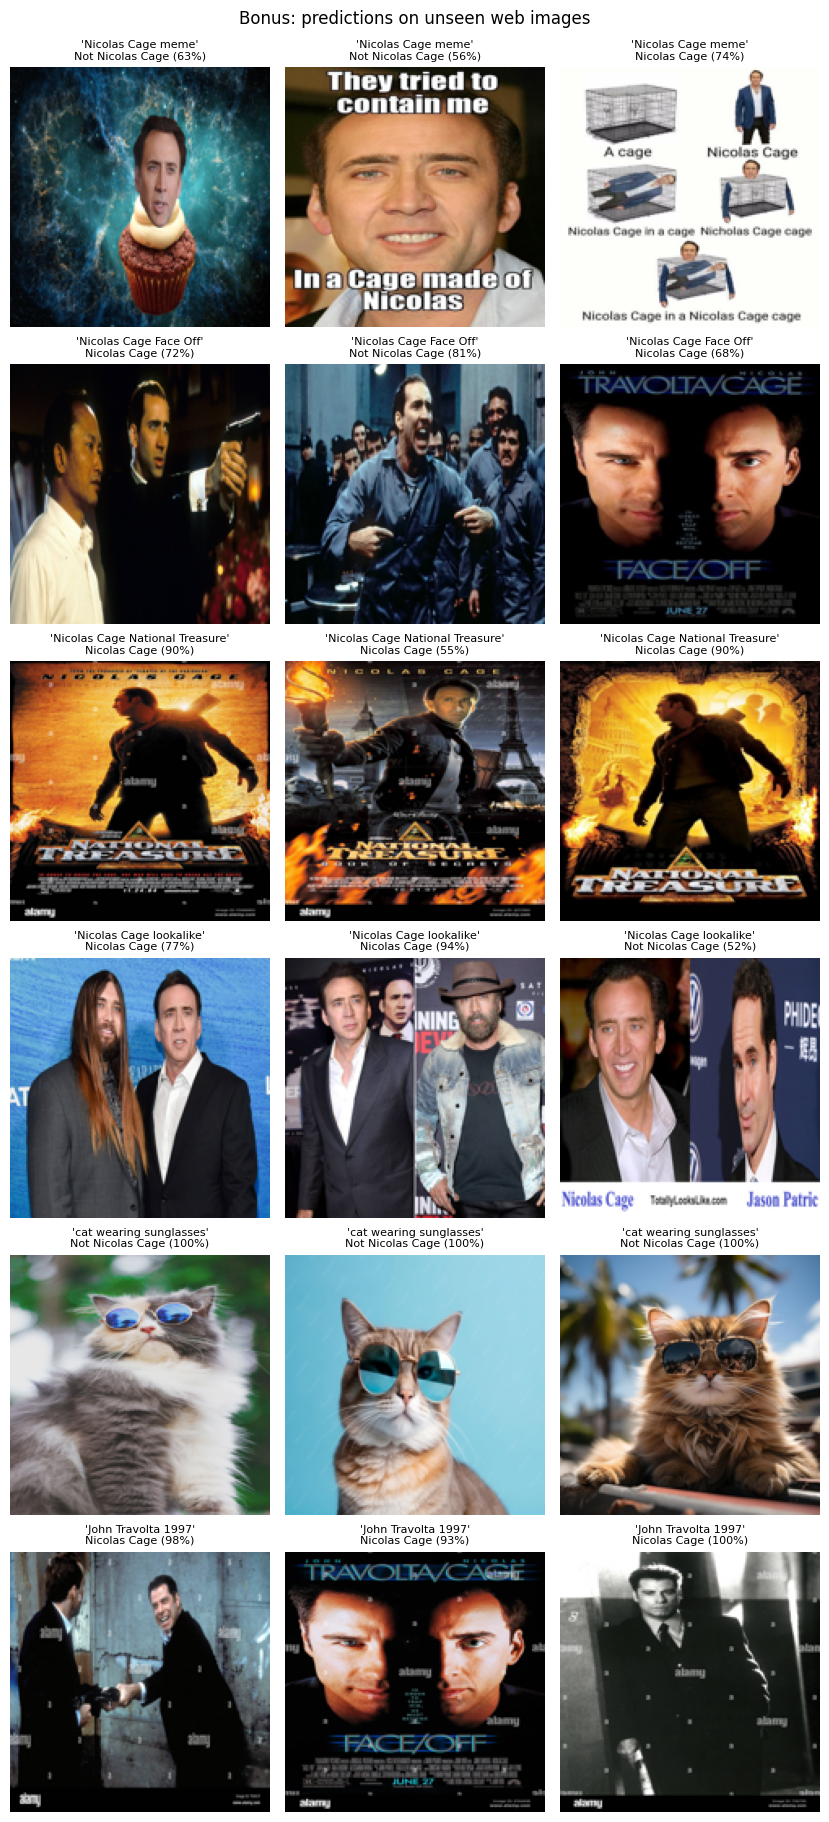

In [9]:
FUN_QUERIES = ["Nicolas Cage meme", "Nicolas Cage Face Off", "Nicolas Cage National Treasure",
               "Nicolas Cage lookalike", "cat wearing sunglasses", "John Travolta 1997"]
PER_QUERY = BONUS_IMAGES // len(FUN_QUERIES)             # 3 per query, 18 in total
tests = []
for q in FUN_QUERIES:
    found = 0
    for url in image_search(q, 15):
        got = fetch_image(url)
        if got and got[0] not in train_hashes:
            tests.append((q, load_image(got[1]))); found += 1
            if found == PER_QUERY: break

rows = [q for q in FUN_QUERIES if any(t[0] == q for t in tests)]
if rows:
    fig, axes = plt.subplots(len(rows), PER_QUERY, figsize=(PER_QUERY * 2.8, len(rows) * 3), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    col = {q: 0 for q in rows}
    for q, img in tests:
        label, conf = predict(img)
        ax = axes[rows.index(q), col[q]]; col[q] += 1
        ax.imshow(img); ax.set_title(f"'{q}'\n{label} ({conf:.0%})", fontsize=8)
    plt.tight_layout(); plt.suptitle("Bonus: predictions on unseen web images", y=1.01)
    plt.savefig("screenshots/bonus_web_predictions.png", dpi=150, bbox_inches="tight"); plt.show()
else:
    print("No new web images could be fetched.")

## Submission files
The screenshots are saved individually (not zipped), as required. In Colab they download automatically.

In [10]:
for f in sorted(glob.glob("screenshots/*.png")):
    print("Saved:", f)
try:
    from google.colab import files
    for f in sorted(glob.glob("screenshots/*.png")):
        files.download(f)
except ImportError:
    print("\nRunning locally: files are in the screenshots/ folder next to this notebook.")

Saved: screenshots/bonus_web_predictions.png
Saved: screenshots/screenshot_1_dataset_examples.png
Saved: screenshots/screenshot_2_training_history.png
Saved: screenshots/screenshot_3_correct_nicolas_cage.png
Saved: screenshots/screenshot_4_correct_not_nicolas_cage.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Reflection
- **Transfer learning:** I used MobileNetV2 because a CNN trained from scratch on a few hundred images tends to overfit, whereas pre-trained features generalise well to faces.
- **Overfitting control:** data augmentation, dropout and early stopping kept the training and validation curves close.
- **Class imbalance:** class weights balanced the loss, as "Not Nicolas Cage" is naturally the larger class.
- **Data quality:** web-sourced labels are noisy (posters, group shots, memes). I reviewed the Cage images and used several queries per class to increase variety.
- **Limitation:** "Not Nicolas Cage" is an open-ended class, so the model can only reject what resembles its training negatives. Look-alikes remain the hardest case.
- **Improvement:** in production, face detection followed by face-embedding comparison (face verification) would be more robust than whole-image classification.

## References
Chollet, F. (2021) *Deep learning with Python*. 2nd edn. Shelter Island, NY: Manning.

Google (2026) *Custom Search JSON API*. Available at: https://developers.google.com/custom-search/v1/overview (Accessed: 1 November 2026).

Sandler, M., Howard, A., Zhu, M., Zhmoginov, A. and Chen, L.-C. (2018) 'MobileNetV2: Inverted residuals and linear bottlenecks', *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, pp. 4510-4520.

SerpAPI (2026) *Google Images API*. Available at: https://serpapi.com/google-images-api (Accessed: 1 November 2026).

TensorFlow (2024) *Transfer learning and fine-tuning*. Available at: https://www.tensorflow.org/tutorials/images/transfer_learning (Accessed: 1 November 2026).